# 03 — HED augmentation at 128×128 data
Compare pretrained ResNet-18 with flips only versus flips + HED strength 0.2.
Start with seed 0. Keep the official test set locked. No 128→224 upsampling here.
Restart the kernel before running this notebook to load the updated src files.


In [1]:
from pathlib import Path
import sys, inspect, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT = Path(r"C:\Users\XiXi\OneDrive\Documents\Stanford\CS230\pathmnist_project")
REPO = PROJECT / "cs230-pathmnist"
DATA = PROJECT / "data"
CHECKPOINTS = PROJECT / "checkpoints"
RESULTS = REPO / "results"
sys.path.insert(0, str(REPO))

from src.data import load_split, GPUPreprocess, hed_jitter, PathMNISTArrays
from src.engine import run_experiment, run_epoch
from src.models import build_model
from src.hed_shift import hed_perturb, show_grid
from src.report import load_results, results_table, plot_history
from torch.utils.data import DataLoader
from skimage.color import rgb2hed, hed2rgb

assert torch.cuda.is_available(), "Select your CUDA-enabled pathmnist environment."
assert "hed_sigma" in inspect.signature(run_experiment).parameters, "Restart kernel and check updated src."
assert (DATA / "pathmnist_128.npz").exists()
RESULTS.mkdir(parents=True, exist_ok=True)
CHECKPOINTS.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
print("Source:", inspect.getfile(run_experiment))

COMMON = dict(data_size=128, batch_size=128, seed=0, num_workers=0,
              data_root=str(DATA), ckpt_dir=str(CHECKPOINTS), results_dir=str(RESULTS))
CONTROL = "resnet18_pretrained_128_seed0"
HED_RUN = "resnet18_pretrained_128_hed20_seed0"

control_path = CHECKPOINTS / f"{CONTROL}.pt"
assert control_path.exists(), f"Missing control checkpoint: {control_path}"
control_cfg = torch.load(control_path, map_location="cpu")["config"]
assert control_cfg["model"] == "resnet18_pretrained"
assert control_cfg["data_size"] == 128 and control_cfg.get("input_size") in (None, 128)
assert control_cfg.get("hed_sigma", 0) == 0
# Prevent accidentally comparing different training recipes.
for key, value in {**COMMON, "lr": 1e-4, "epochs": 30}.items():
    if key not in ("data_root", "ckpt_dir", "results_dir", "num_workers"):
        assert control_cfg[key] == value, (key, control_cfg[key], value)
print("Control configuration checked.")


GPU: NVIDIA GeForce RTX 5090
Source: C:\Users\XiXi\OneDrive\Documents\Stanford\CS230\pathmnist_project\cs230-pathmnist\src\engine.py
Control configuration checked.


## 1. Check augmentation math and appearance
The fixed-factor GPU result should match scikit-image closely. Inspect the preview before training.


Maximum absolute difference: 2.1571910246986903e-07


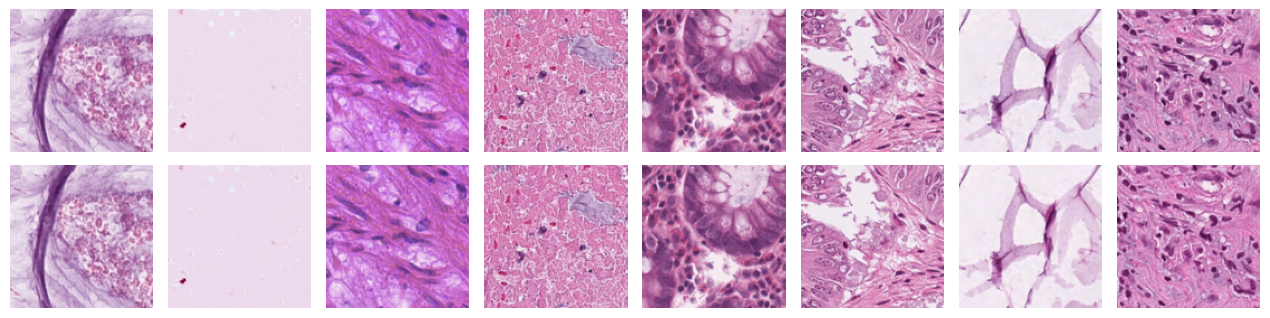

In [2]:
val_images, labels = load_split(str(DATA), 128, "val")
sample = np.array(val_images[:32])
xt = torch.from_numpy(sample).permute(0, 3, 1, 2).float().to(device) / 255
prep = GPUPreprocess(device, hed_sigma=0.2)
alpha = torch.tensor([1.2, 0.8, 1.0], device=device).view(1, 3, 1, 1)
with torch.no_grad():
    gpu = hed_jitter(xt, 0.2, prep.hed_from_rgb, prep.rgb_from_hed, alpha=alpha)
reference = rgb2hed(sample)
reference *= np.array([1.2, 0.8, 1.0])
reference = np.clip(hed2rgb(reference), 0, 1)
error = np.abs(gpu.permute(0, 2, 3, 1).cpu().numpy() - reference).max()
print("Maximum absolute difference:", error)
assert error < 1e-5
preview = hed_perturb(sample, sigma=0.2, seed=0, chunk=32)
show_grid(sample, preview)
plt.show()


## 2. Short smoke test
Two epochs, ten batches per split. These are pipeline checks, not benchmark scores.


In [3]:
smoke = run_experiment(
    "resnet18_pretrained_128_hed20_smoke", "resnet18_pretrained",
    hed_sigma=0.2, lr=1e-4, epochs=2, limit_batches=10, save=True, **COMMON)


=== resnet18_pretrained_128_hed20_smoke: resnet18_pretrained, data 128x128, network input 128x128, HED aug 0.2, seed 0, 11.18M params, device cuda ===
ep 01 | lr 1.0e-04 | train loss 1.426 acc 0.559 F1 0.538 | val loss 0.758 acc 0.807 F1 0.797 | 13s  *best
ep 02 | lr 1.0e-04 | train loss 0.466 acc 0.878 F1 0.878 | val loss 0.311 acc 0.919 F1 0.915 | 0s  *best
Best epoch 2: val acc 0.9187, val macro-F1 0.9149, 7s/epoch train, 24670 img/s inference. Saved: C:\Users\XiXi\OneDrive\Documents\Stanford\CS230\pathmnist_project\cs230-pathmnist\results\resnet18_pretrained_128_hed20_smoke.json



## 3. Full HED training
### 3.1 Test training on ResNet18_pretained model, with lr = 1e-4
Reuses a completed result if present. Stops rather than overwriting an existing incomplete run.
Training uses HED plus flips; validation stays clean. Best checkpoint is selected on clean validation macro-F1.


=== resnet18_pretrained_128_hed20_seed0: resnet18_pretrained, data 128x128, network input 128x128, HED aug 0.2, seed 0, 11.18M params, device cuda ===
ep 01 | lr 1.0e-04 | train loss 0.120 acc 0.962 F1 0.962 | val loss 0.041 acc 0.987 F1 0.987 | 27s  *best
ep 02 | lr 1.0e-04 | train loss 0.043 acc 0.986 F1 0.986 | val loss 0.034 acc 0.988 F1 0.988 | 25s  *best
ep 03 | lr 1.0e-04 | train loss 0.031 acc 0.990 F1 0.990 | val loss 0.030 acc 0.990 F1 0.990 | 25s  *best
ep 04 | lr 1.0e-04 | train loss 0.024 acc 0.992 F1 0.992 | val loss 0.025 acc 0.992 F1 0.992 | 25s  *best
ep 05 | lr 1.0e-04 | train loss 0.022 acc 0.993 F1 0.993 | val loss 0.052 acc 0.983 F1 0.983 | 25s
ep 06 | lr 1.0e-04 | train loss 0.021 acc 0.993 F1 0.993 | val loss 0.047 acc 0.985 F1 0.985 | 25s
ep 07 | lr 1.0e-04 | train loss 0.017 acc 0.994 F1 0.994 | val loss 0.024 acc 0.991 F1 0.991 | 26s
ep 08 | lr 3.0e-05 | train loss 0.007 acc 0.998 F1 0.998 | val loss 0.012 acc 0.996 F1 0.996 | 25s  *best
ep 09 | lr 3.0e-05 | t

,model,data,net input,params (M),best epoch,epochs run,val acc,val macro-F1,train s/epoch,inference img/s,status
run,,,,,,,,,,,
resnet18_pretrained_128_seed0,resnet18_pretrained,128,128,11.18,29,30,0.9990,0.9990,9.2,27284,done
resnet18_pretrained_128_hed20_seed0,resnet18_pretrained,128,128,11.18,29,30,0.9982,0.9982,24.9,24145,done


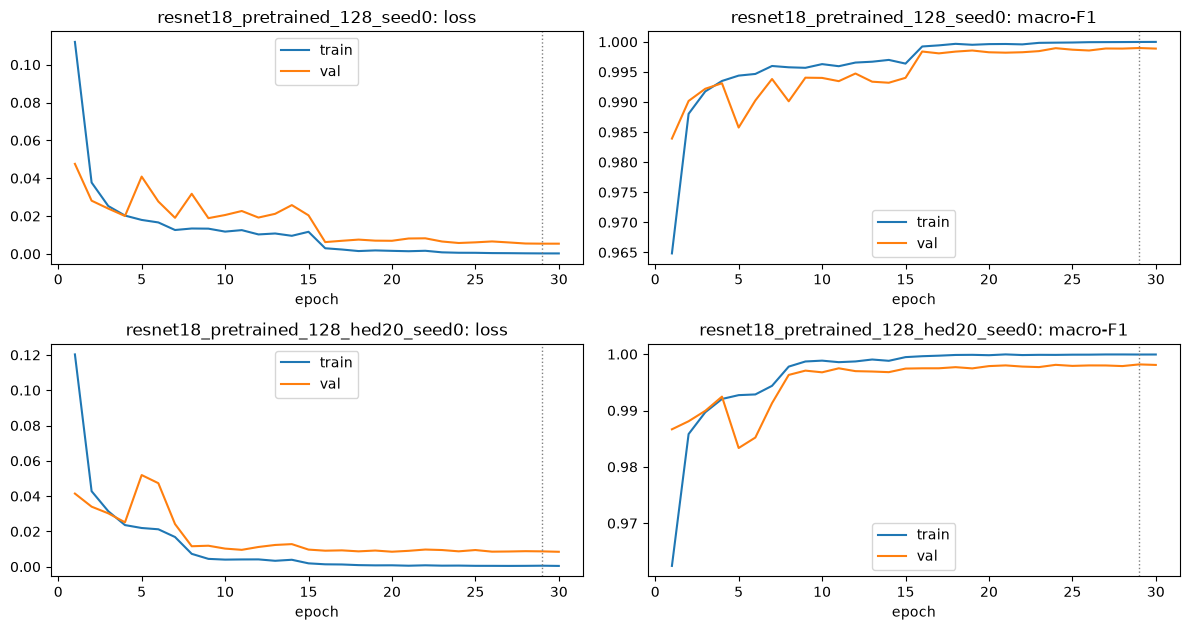

In [4]:
result_path = RESULTS / f"{HED_RUN}.json"
if result_path.exists():
    hed_result = json.loads(result_path.read_text())
    assert hed_result.get("status") == "done", "Incomplete run exists: preserve it and choose a new run name."
    assert (CHECKPOINTS / f"{HED_RUN}.pt").exists()
    print("Loaded completed run:", HED_RUN)
else:
    assert not (CHECKPOINTS / f"{HED_RUN}.pt").exists(), "Checkpoint already exists; choose a new run name."
    hed_result = run_experiment(
        HED_RUN, "resnet18_pretrained", hed_sigma=0.2,
        lr=1e-4, epochs=30, save=True, **COMMON)

runs = load_results([CONTROL, HED_RUN], results_dir=str(RESULTS))
display(results_table(runs))
plot_history(runs)
plt.show()


### 3.2 Test training on ResNet18 scratch model, with lr = 1e-3

=== resnet18_scratch_128_hed20_seed0: resnet18_scratch, data 128x128, network input 128x128, HED aug 0.2, seed 0, 11.18M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 0.444 acc 0.843 F1 0.841 | val loss 0.442 acc 0.844 F1 0.832 | 27s  *best
ep 02 | lr 1.0e-03 | train loss 0.194 acc 0.935 F1 0.935 | val loss 0.151 acc 0.950 F1 0.948 | 25s  *best
ep 03 | lr 1.0e-03 | train loss 0.152 acc 0.949 F1 0.949 | val loss 0.330 acc 0.899 F1 0.889 | 25s
ep 04 | lr 1.0e-03 | train loss 0.133 acc 0.954 F1 0.954 | val loss 0.559 acc 0.825 F1 0.805 | 25s
ep 05 | lr 1.0e-03 | train loss 0.117 acc 0.961 F1 0.961 | val loss 0.463 acc 0.841 F1 0.842 | 25s
ep 06 | lr 3.0e-04 | train loss 0.066 acc 0.978 F1 0.978 | val loss 0.069 acc 0.978 F1 0.977 | 25s  *best
ep 07 | lr 3.0e-04 | train loss 0.061 acc 0.979 F1 0.979 | val loss 0.122 acc 0.963 F1 0.963 | 26s
ep 08 | lr 3.0e-04 | train loss 0.058 acc 0.980 F1 0.980 | val loss 0.158 acc 0.949 F1 0.947 | 25s
ep 09 | lr 3.0e-04 | train loss 0.053 acc 

,model,data,net input,params (M),best epoch,epochs run,val acc,val macro-F1,train s/epoch,inference img/s,status
run,,,,,,,,,,,
resnet18_scratch_128_seed0,resnet18_scratch,128,128,11.18,30,30,0.9967,0.9966,9.3,20106,done
resnet18_scratch_128_hed20_seed0,resnet18_scratch,128,128,11.18,19,25,0.9942,0.9942,25.0,25838,done


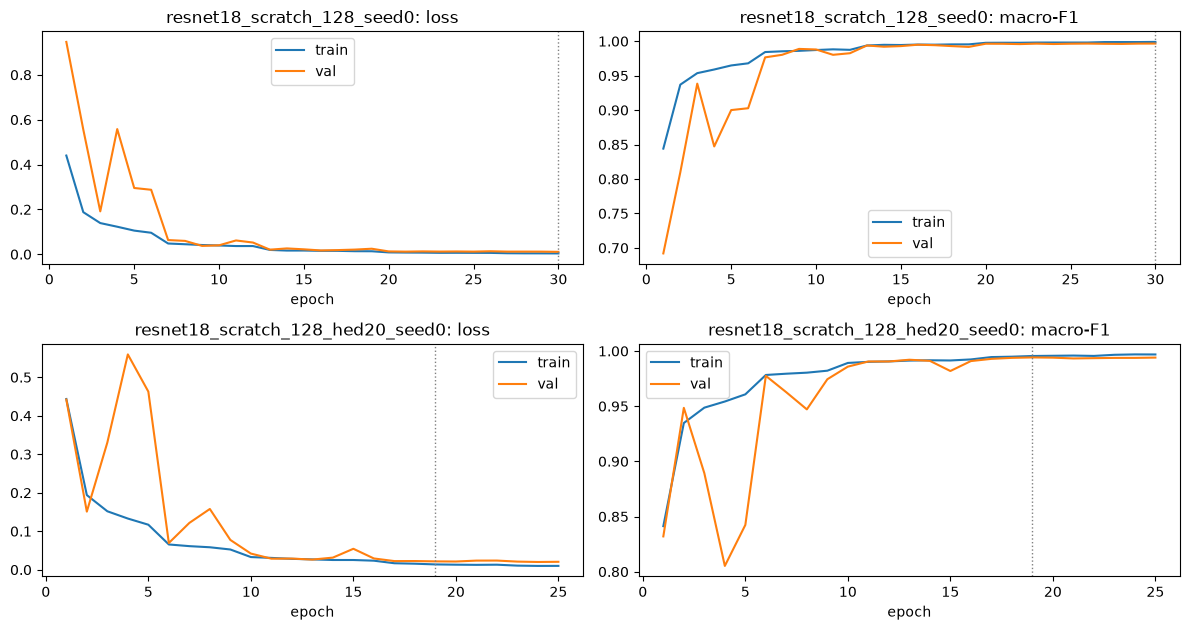

In [6]:
CONTROL = "resnet18_scratch_128_seed0"
HED_RUN = "resnet18_scratch_128_hed20_seed0"

result_path = RESULTS / f"{HED_RUN}.json"
checkpoint_path = CHECKPOINTS / f"{HED_RUN}.pt"

if result_path.exists():
    hed_result = json.loads(result_path.read_text())

    assert hed_result.get("status") == "done", (
        "Incomplete run exists. Preserve its files and choose a new run name."
    )
    assert checkpoint_path.exists(), "Missing checkpoint."

    print("Loaded completed run:", HED_RUN)

else:
    assert not checkpoint_path.exists(), (
        "Checkpoint already exists. Choose a new run name."
    )

    hed_result = run_experiment(
        name=HED_RUN,
        model="resnet18_scratch",
        hed_sigma=0.2,
        lr=1e-3,
        epochs=30,
        save=True,
        **COMMON,
    )

runs = load_results(
    [CONTROL, HED_RUN],
    results_dir=str(RESULTS),
)

display(results_table(runs))
plot_history(runs)
plt.show()

### 3.3 Test training on baseline CNN model, with lr = 1e-3

=== baseline_cnn_128_hed20_seed0: baseline_cnn, data 128x128, network input 128x128, HED aug 0.2, seed 0, 0.39M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 0.383 acc 0.870 F1 0.867 | val loss 0.661 acc 0.802 F1 0.797 | 40s  *best
ep 02 | lr 1.0e-03 | train loss 0.168 acc 0.944 F1 0.944 | val loss 0.263 acc 0.912 F1 0.903 | 41s  *best
ep 03 | lr 1.0e-03 | train loss 0.135 acc 0.956 F1 0.955 | val loss 0.234 acc 0.920 F1 0.916 | 42s  *best
ep 04 | lr 1.0e-03 | train loss 0.115 acc 0.962 F1 0.961 | val loss 0.259 acc 0.916 F1 0.914 | 42s
ep 05 | lr 1.0e-03 | train loss 0.103 acc 0.966 F1 0.966 | val loss 0.302 acc 0.900 F1 0.898 | 40s
ep 06 | lr 1.0e-03 | train loss 0.094 acc 0.969 F1 0.969 | val loss 0.452 acc 0.856 F1 0.851 | 41s
ep 07 | lr 3.0e-04 | train loss 0.061 acc 0.981 F1 0.981 | val loss 0.055 acc 0.982 F1 0.982 | 40s  *best
ep 08 | lr 3.0e-04 | train loss 0.056 acc 0.983 F1 0.983 | val loss 0.043 acc 0.987 F1 0.986 | 40s  *best
ep 09 | lr 3.0e-04 | train loss 0.053

,model,data,net input,params (M),best epoch,epochs run,val acc,val macro-F1,train s/epoch,inference img/s,status
run,,,,,,,,,,,
baseline_cnn_128_seed0,baseline_cnn,128,128,0.39,24,30,0.9963,0.9963,9.0,30394,done
baseline_cnn_128_hed20_seed0,baseline_cnn,128,128,0.39,22,28,0.9946,0.9946,40.0,28443,done


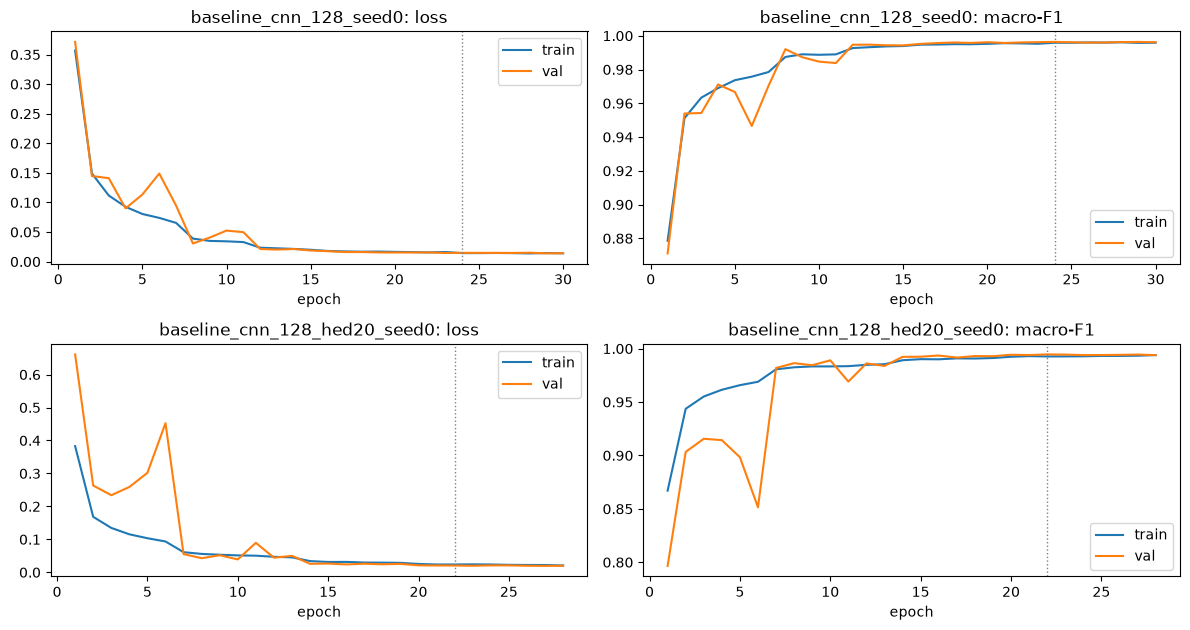

In [8]:
CONTROL = "baseline_cnn_128_seed0"
HED_RUN = "baseline_cnn_128_hed20_seed0"

result_path = RESULTS / f"{HED_RUN}.json"
checkpoint_path = CHECKPOINTS / f"{HED_RUN}.pt"

if result_path.exists():
    hed_result = json.loads(result_path.read_text())

    assert hed_result.get("status") == "done", (
        "Incomplete run exists. Preserve its files and choose a new run name."
    )
    assert checkpoint_path.exists(), "Missing checkpoint."
    assert hed_result["config"]["model"] == "baseline_cnn"

    print("Loaded completed run:", HED_RUN)

else:
    assert not checkpoint_path.exists(), (
        "Checkpoint already exists. Choose a new run name."
    )

    hed_result = run_experiment(
        name=HED_RUN,
        model="baseline_cnn",
        hed_sigma=0.2,
        lr=1e-3,
        epochs=30,
        save=True,
        **COMMON,
    )

runs = load_results(
    [CONTROL, HED_RUN],
    results_dir=str(RESULTS),
)

display(results_table(runs))
plot_history(runs)
plt.show()

## 4. Clean and simulated-stain validation evaluation
Evaluate one version at a time to limit RAM usage, using Windows-friendly num_workers=0.
HED strength 0 is a conversion-only control, not necessarily identical to the original RGB image.
The same perturbation seed produces identical evaluation images for both models.
Scores remain unrounded in the CSV. Synthetic robustness does not establish real cross-center generalization.


### 4.1 ResNet18 pretrained model

In [5]:
CONTROL = "resnet18_pretrained_128_seed0"
HED_RUN = "resnet18_pretrained_128_hed20_seed0"
rows = []
for strength in [None, 0.0, 0.15, 0.30]:
    version = "clean" if strength is None else f"hed_{strength:.2f}"
    print("Evaluating:", version, flush=True)
    imgs = val_images if strength is None else hed_perturb(
        val_images, sigma=strength, seed=0, chunk=64)
    loader = DataLoader(PathMNISTArrays(imgs, labels), batch_size=256,
                        shuffle=False, num_workers=0, pin_memory=True)
    for name in [CONTROL, HED_RUN]:
        ckpt = torch.load(CHECKPOINTS / f"{name}.pt", map_location="cpu")
        cfg = ckpt["config"]
        # Reconstruct without downloading ImageNet weights; checkpoint supplies all weights.
        net = build_model("resnet18_scratch").to(device)
        net.load_state_dict(ckpt["model_state"])
        eval_prep = GPUPreprocess(device, out_size=cfg.get("input_size"), hed_sigma=0)
        metrics = run_epoch(net, loader, eval_prep, device, train=False, amp=cfg.get("amp", True))
        rows.append(dict(run=name, version=version, seed=cfg["seed"],
                         eval_seed=0, train_hed=cfg.get("hed_sigma", 0),
                         macro_f1=metrics["macro_f1"], accuracy=metrics["accuracy"]))
        del net, ckpt
    del loader, imgs

table = pd.DataFrame(rows)
table.to_csv(RESULTS / "hed_aug_128_pretrained_seed0_eval.csv", index=False)
comparison = table.pivot(index="version", columns="run", values="macro_f1")
comparison["HED minus control"] = comparison[HED_RUN] - comparison[CONTROL]
display(comparison)


Evaluating: clean
Evaluating: hed_0.00
Evaluating: hed_0.15
Evaluating: hed_0.30


run,resnet18_pretrained_128_hed20_seed0,resnet18_pretrained_128_seed0,HED minus control
version,,,
clean,0.998181,0.998973,-0.000792
hed_0.00,0.998270,0.998865,-0.000594
hed_0.15,0.997858,0.995347,0.002511
hed_0.30,0.997351,0.976489,0.020862


### 4.2 ResNet18 scratch model

In [9]:
CONTROL = "resnet18_scratch_128_seed0"
HED_RUN = "resnet18_scratch_128_hed20_seed0"
rows = []
for strength in [None, 0.0, 0.15, 0.30]:
    version = "clean" if strength is None else f"hed_{strength:.2f}"
    print("Evaluating:", version, flush=True)
    imgs = val_images if strength is None else hed_perturb(
        val_images, sigma=strength, seed=0, chunk=64)
    loader = DataLoader(PathMNISTArrays(imgs, labels), batch_size=256,
                        shuffle=False, num_workers=0, pin_memory=True)
    for name in [CONTROL, HED_RUN]:
        ckpt = torch.load(CHECKPOINTS / f"{name}.pt", map_location="cpu")
        cfg = ckpt["config"]
        # Reconstruct without downloading ImageNet weights; checkpoint supplies all weights.
        net = build_model("resnet18_scratch").to(device)
        net.load_state_dict(ckpt["model_state"])
        eval_prep = GPUPreprocess(device, out_size=cfg.get("input_size"), hed_sigma=0)
        metrics = run_epoch(net, loader, eval_prep, device, train=False, amp=cfg.get("amp", True))
        rows.append(dict(run=name, version=version, seed=cfg["seed"],
                         eval_seed=0, train_hed=cfg.get("hed_sigma", 0),
                         macro_f1=metrics["macro_f1"], accuracy=metrics["accuracy"]))
        del net, ckpt
    del loader, imgs

table = pd.DataFrame(rows)
table.to_csv(RESULTS / "hed_aug_128_scratch_seed0_eval.csv", index=False)
comparison = table.pivot(index="version", columns="run", values="macro_f1")
comparison["HED minus control"] = comparison[HED_RUN] - comparison[CONTROL]
display(comparison)


Evaluating: clean
Evaluating: hed_0.00
Evaluating: hed_0.15
Evaluating: hed_0.30


run,resnet18_scratch_128_hed20_seed0,resnet18_scratch_128_seed0,HED minus control
version,,,
clean,0.994188,0.996584,-0.002397
hed_0.00,0.994103,0.996279,-0.002176
hed_0.15,0.993644,0.987399,0.006245
hed_0.30,0.992683,0.930849,0.061833


### 4.3 Baseline CNN model

In [10]:
CONTROL = "baseline_cnn_128_seed0"
HED_RUN = "baseline_cnn_128_hed20_seed0"
rows = []
for strength in [None, 0.0, 0.15, 0.30]:
    version = "clean" if strength is None else f"hed_{strength:.2f}"
    print("Evaluating:", version, flush=True)
    imgs = val_images if strength is None else hed_perturb(
        val_images, sigma=strength, seed=0, chunk=64)
    loader = DataLoader(PathMNISTArrays(imgs, labels), batch_size=256,
                        shuffle=False, num_workers=0, pin_memory=True)
    for name in [CONTROL, HED_RUN]:
        ckpt = torch.load(CHECKPOINTS / f"{name}.pt", map_location="cpu")
        cfg = ckpt["config"]
        # Reconstruct without downloading ImageNet weights; checkpoint supplies all weights.
        net = build_model("baseline_cnn").to(device)
        net.load_state_dict(ckpt["model_state"])
        eval_prep = GPUPreprocess(device, out_size=cfg.get("input_size"), hed_sigma=0)
        metrics = run_epoch(net, loader, eval_prep, device, train=False, amp=cfg.get("amp", True))
        rows.append(dict(run=name, version=version, seed=cfg["seed"],
                         eval_seed=0, train_hed=cfg.get("hed_sigma", 0),
                         macro_f1=metrics["macro_f1"], accuracy=metrics["accuracy"]))
        del net, ckpt
    del loader, imgs

table = pd.DataFrame(rows)
table.to_csv(RESULTS / "hed_aug_128_baseline_seed0_eval.csv", index=False)
comparison = table.pivot(index="version", columns="run", values="macro_f1")
comparison["HED minus control"] = comparison[HED_RUN] - comparison[CONTROL]
display(comparison)

Evaluating: clean
Evaluating: hed_0.00
Evaluating: hed_0.15
Evaluating: hed_0.30


run,baseline_cnn_128_hed20_seed0,baseline_cnn_128_seed0,HED minus control
version,,,
clean,0.994582,0.996347,-0.001766
hed_0.00,0.994288,0.996340,-0.002052
hed_0.15,0.994182,0.988719,0.005463
hed_0.30,0.992782,0.934300,0.058482
